In [9]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
import pickle
import ast
from functools import reduce
from tqdm.auto import tqdm
import networkx as nx

import sys
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools
from pandarallel import pandarallel
pandarallel.initialize(progress_bar=True)
sys.path.append('/home/mattia/geass')
import utils
from annotator import calculate_fp
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import tmap as tm

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

# sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
# from aiddtools import fingerprint_tools as fpt
clear_output()

## Calculate MAP4 fingerprints

In [ ]:
df_NPA = pd.read_csv('/home/mattia/geass/data/NPAtlas_filtered.csv', low_memory=False)
PandasTools.AddMoleculeColumnToFrame(df_NPA, 'ISOSMILES')
df_NPA['FP_map4'] = df_NPA['ROMol'].parallel_apply(lambda mol: calculate_fp(mol, 'map4'))
df_NPA = df_NPA.rename(columns={'npaid': 'NPA_ID', 'compound_cluster_id': 'Cluster_ID'})
df_map4 = df_NPA[['NPA_ID', 'ISOSMILES', 'Cluster_ID', 'FP_map4']]
df_map4.to_pickle('/home/mattia/geass/NPA_analysis/NPA_map4.pkl')

## Classify NPA compounds

In [ ]:
import json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import quote
from urllib.request import urlopen
from time import sleep

def _top_label(obj):
    if obj is None:
        return None
    if isinstance(obj, dict):
        for key in ('name', 'label', 'class', 'superclass', 'pathway'):
            val = obj.get(key)
            if val:
                return val
        return next(iter(obj.values()), None)
    if isinstance(obj, list):
        if not obj:
            return None
        first = obj[0]
        if isinstance(first, dict):
            return _top_label(first)
        if isinstance(first, (list, tuple)) and first:
            return first[-1]
        return first
    return obj

def classify_npclassifier(smiles):
    url = f'https://npclassifier.gnps2.org/classify?smiles={quote(smiles)}'
    data = json.loads(urlopen(url, timeout=30).read().decode('utf-8'))
    return {
        'NPClassifier_Pathway': _top_label(data.get('pathway_results')),
        'NPClassifier_Superclass': _top_label(data.get('superclass_results')),
        'NPClassifier_Class': _top_label(data.get('class_results'))}

df_npclassifier = df_NPA[['NPA_ID', 'ISOSMILES']]
out_dir = Path('/home/mattia/geass/NPA_visualisation')
batch_size = 2000
batch_results = []
for i, start in enumerate(range(0, len(df_npclassifier), batch_size), start=1):
    batch = df_npclassifier.iloc[start:start + batch_size].reset_index(drop=True).copy()
    with ThreadPoolExecutor(max_workers=8) as pool:
        results = list(tqdm(pool.map(classify_npclassifier, batch['ISOSMILES']), total=len(batch)))
    batch = pd.concat([batch, pd.DataFrame(results).reset_index(drop=True)], axis=1)
    batch.to_csv(out_dir / f'npclassifier_batch_{i:03d}.csv', index=False)
    sleep(30)

In [ ]:
from pathlib import Path
import pandas as pd
import tarfile

out_dir = Path('/home/mattia/geass/NPA_visualisation')
files = sorted(out_dir.glob('npclassifier_batch_*.csv'))

df_npclassifier = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)

with tarfile.open(out_dir / 'npclassifier_batches.tar.gz', 'w:gz') as tar:
    for f in files:
        tar.add(f, arcname=f.name)

df_npclassifier.to_csv(out_dir / 'NPA_npclassifier.csv', index=False)

## Visualise NP Atlas with TMAP

In [ ]:
# Create TMAP layout
df_map4 = pd.read_pickle('/home/mattia/geass/NPA_analysis/NPA_map4.pkl')

fps = df_map4['FP_map4'].tolist()
fps_ = [tm.VectorUint(np.array(fp, dtype=np.uint32)) for fp in fps]

lf = tm.LSHForest(1024, 32)
lf.batch_add(fps_)
lf.index()

cfg = tm.LayoutConfiguration()
cfg.node_size = 1 / 25
cfg.mmm_repeats = 2
cfg.sl_extra_scaling_steps = 5
cfg.k = 20
cfg.sl_scaling_type = tm.RelativeToAvgLength

x, y, s, t, gp = tm.layout_from_lsh_forest(lf, cfg)
df_map4 = df_map4.assign(x=list(x), y=list(y))

df_npclassifier = pd.read_csv(out_dir / 'NPA_npclassifier.csv')
df_map4 = df_map4.merge(df_npclassifier, on=['NPA_ID', 'ISOSMILES'], how='left')

df_map4.drop(columns=['FP_map4']).to_parquet('/home/mattia/geass/NPA_analysis/NPA_tmap_nodes.parquet', index=False)
np.savez('/home/mattia/geass/NPA_analysis/NPA_tmap_edges.npz', s=np.asarray(list(s), dtype=np.int32), t=np.asarray(list(t), dtype=np.int32))

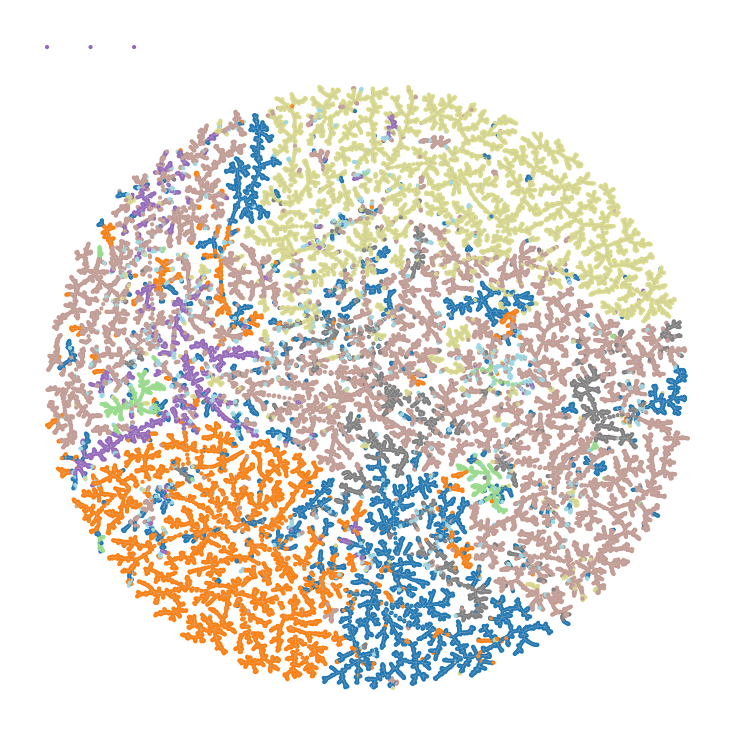

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

nodes = pd.read_parquet('/home/mattia/geass/NPA_analysis/NPA_tmap_nodes.parquet')
edges = np.load('/home/mattia/geass/NPA_analysis/NPA_tmap_edges.npz')

codes = pd.Categorical(nodes['NPClassifier_Pathway'].fillna('Unknown')).codes
xv = nodes['x'].to_numpy()
yv = nodes['y'].to_numpy()
segments = [((xv[a], yv[a]), (xv[b], yv[b])) for a, b in zip(edges['s'], edges['t'])]

fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
ax.add_collection(LineCollection(segments, colors='0.75', linewidths=0.4, alpha=0.35))
ax.scatter(xv, yv, s=4, c=codes, cmap=plt.cm.tab20, edgecolors='none')

ax.set_axis_off()
ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

## Clustering NP Atlas with MAP4

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
# Load similarity matrix
with open("NPA_map4_similarity_filtered.pkl", "rb") as f:
    data = pickle.load(f)
ids = np.array(data["ids"])
sim_matrix = np.asarray(data["sim_matrix"], dtype=np.float32)

dist = 1.0 - sim_matrix
dist = ((dist + dist.T) * 0.5).astype(np.float32, copy=False)
np.fill_diagonal(dist, 0.0)

iu = np.triu_indices(dist.shape[0], k=1)
condensed = dist[iu].astype(np.float64, copy=False)

Z = linkage(condensed, method="average")

In [ ]:
df_fragments = pd.read_pickle("NPA_fragments_ann.pkl")
df_clusters = pd.DataFrame({"NPA_ID": ids})

leaf_order = dendrogram(Z, no_plot=True)["leaves"]

for t in np.round(np.linspace(0.20, 0.90, 15), 2):
    # Cut dendrogram at distance threshold
    clusters = fcluster(Z, t=t, criterion="distance")

    # Reorder cluster ids according to dendrogram leaf order
    ordered_clusters = clusters[leaf_order]
    cluster_map = {cid: i + 1 for i, cid in enumerate(pd.unique(ordered_clusters))}
    clusters = np.array([cluster_map[c] for c in clusters])

    df_clusters[f"cluster_id_t{int(t * 100):02d}"] = clusters

df_clusters = df_fragments[['NPA_ID','ISOSMILES']].merge(df_clusters, on="NPA_ID", how="right")
df_clusters.to_pickle("df_clusters_map4.pkl")

In [ ]:
# Sihouette analysis
from sklearn.metrics import silhouette_score
df_clusters_map4 = pd.read_pickle("df_clusters_map4.pkl")
with open('NPA_map4_similarity_filtered.pkl', 'rb') as f:
    data = pickle.load(f)

sim_matrix = np.asarray(data['sim_matrix'], dtype=np.float32)

dist = 1.0 - sim_matrix
dist = ((dist + dist.T) * 0.5).astype(np.float32, copy=False)
np.fill_diagonal(dist, 0.0)

cluster_cols = [c for c in df_clusters_map4.columns if c.startswith('cluster_id_t')]

from sklearn.metrics import silhouette_score

results = []

for col in cluster_cols:

    labels = df_clusters_map4[col].values
    n_clusters = len(np.unique(labels))

    if n_clusters > 1:
        score = silhouette_score(dist, labels, metric='precomputed')
    else:
        score = np.nan

    results.append({
        'column': col,
        'threshold': int(col.split('t')[-1]) / 100,
        'n_clusters': n_clusters,
        'silhouette': score
    })

df_silhouette = pd.DataFrame(results).sort_values('threshold')
print(df_silhouette)

In [ ]:
sizes = df_clusters_map4['cluster_id_t50'].value_counts()
singletons = (sizes == 1).sum()
pairs = (sizes == 2).sum()

print(singletons, pairs)

In [ ]:
# import matplotlib.pyplot as plt

# plt.figure()

# plt.plot(df_scan["t"], df_scan["mean_cluster_size_sgo"], label="mean_size SGO")
# plt.plot(df_scan["t"], df_scan["mean_cluster_size_map4"], label="mean_size MAP4")

# plt.plot(df_scan["t"], df_scan["max_cluster_size_sgo"], label="max_size SGO")
# plt.plot(df_scan["t"], df_scan["max_cluster_size_map4"], label="max_size MAP4")

# plt.xlabel("t")
# plt.ylabel("cluster statistics")
# plt.yscale("log")
# plt.legend()

# plt.show()

## Compare MAP4 and SGO

In [ ]:
# Keep fragmented mols with at least 2 annotated fragments (methyls and acetyls are neglected)
df_fragments = pd.read_pickle("../NPA_fragmentation/NPA_fragments_map4.pkl")
# df_frag_stats = df_fragments[df_fragments['Frag_ISOSMILES'].apply(lambda x: len(x) > 1)]
df_frag_stats = df_fragments[['NPA_ID', 'ISOSMILES', 'Frag_IDs', 'Frag_ISOSMILES']].copy()

# df_frag_stats = df_frag_stats[['NPA_ID', 'ISOSMILES', 'Frag_IDs', 'Frag_ISOSMILES']]
# df_frag_stats['N_MU'] = df_frag_stats['Frag_IDs'].apply(
#     lambda lst: sum(x.startswith(('C', 'L')) for x in lst))
# df_frag_stats['N_U'] = df_frag_stats['Frag_IDs'].apply(
#     lambda lst: sum(x.startswith('U') for x in lst))

# alk = {"C00019", "C00033", "C00132"}
# df_frag_stats["N_alk"] = df_frag_stats["Frag_IDs"].apply(
#     lambda lst: sum(x in alk for x in lst))
# df_frag_stats['N_non_alk'] = df_frag_stats['Frag_IDs'].apply(
#     lambda lst: sum(x not in alk for x in lst))

# mask = ~((df_frag_stats['N_non_alk'] == 1) & (df_frag_stats['N_alk'] >= 1))
# df_frag_stats = df_frag_stats[mask]
# mask = df_frag_stats['N_non_alk'] != df_frag_stats['N_U']
# df_frag_stats = df_frag_stats[mask]
# mask = df_frag_stats['N_U'] < df_frag_stats['N_MU']
# df_frag_stats = df_frag_stats[mask]

PandasTools.AddMoleculeColumnToFrame(df_frag_stats, 'ISOSMILES')
df_frag_stats['ISOSMILES'] = df_frag_stats['ROMol'].apply(lambda mol: Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True))
df_frag_stats = df_frag_stats.drop_duplicates(subset='ISOSMILES')

In [ ]:
df_clusters_map4 = pd.read_pickle("df_clusters_map4.pkl")
df_clusters_sgo = pd.read_pickle("../NPA_subgraphs/prep_files/df_clusters_sgo.pkl")

df_clusters_map4 = df_clusters_map4[df_clusters_map4['NPA_ID'].isin(df_frag_stats['NPA_ID'])]
df_clusters_sgo = df_clusters_sgo[df_clusters_sgo['NPA_ID'].isin(df_frag_stats['NPA_ID'])]

In [ ]:
# from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

# map4_cols = [c for c in df_clusters_map4.columns if c.startswith("cluster_id_t")]
# sgo_cols = [c for c in df_clusters_sgo.columns if c.startswith("cluster_id_t")]

# rows = []

# for cluster_col_sgo in sgo_cols:
#     largest_cluster = df_clusters_sgo[cluster_col_sgo].value_counts().idxmax()

#     df_sgo_struct = df_clusters_sgo[df_clusters_sgo[cluster_col_sgo] != largest_cluster][
#         ["NPA_ID", cluster_col_sgo]
#     ].rename(columns={cluster_col_sgo: "cluster_id_sgo"})

#     for cluster_col_map4 in map4_cols:
#         df_map4_tmp = df_clusters_map4[["NPA_ID", cluster_col_map4]].rename(
#             columns={cluster_col_map4: "cluster_id_map4"}
#         )

#         df_cmp = df_sgo_struct.merge(df_map4_tmp, on="NPA_ID", how="inner")

#         labels_sgo = df_cmp["cluster_id_sgo"].to_numpy()
#         labels_map4 = df_cmp["cluster_id_map4"].to_numpy()

#         same_sgo = labels_sgo[:, None] == labels_sgo
#         same_map4 = labels_map4[:, None] == labels_map4

#         np.fill_diagonal(same_sgo, False)
#         np.fill_diagonal(same_map4, False)

#         intersection = (same_sgo & same_map4).sum()
#         union = (same_sgo | same_map4).sum()
#         jaccard_pairs = intersection / union if union > 0 else np.nan

#         ari = adjusted_rand_score(labels_sgo, labels_map4)
#         ami = adjusted_mutual_info_score(labels_sgo, labels_map4)

#         rows.append({
#             "cluster_col_sgo": cluster_col_sgo,
#             "cluster_col_map4": cluster_col_map4,
#             "n_shared": len(df_cmp),
#             "jaccard_pairs": jaccard_pairs,
#             "ari": ari,
#             "ami": ami
#         })

# df_scan_overlap = pd.DataFrame(rows)

In [ ]:
# heatmap_df = df_scan_overlap.pivot(
#     index="cluster_col_sgo",
#     columns="cluster_col_map4",
#     values="jaccard_pairs"
# )

# import matplotlib.pyplot as plt

# plt.figure()

# plt.imshow(heatmap_df.values, cmap="RdYlGn")


# plt.xticks(
#     range(len(heatmap_df.columns)),
#     heatmap_df.columns,
#     rotation=90
# )

# plt.yticks(
#     range(len(heatmap_df.index)),
#     heatmap_df.index
# )

# plt.xlabel("MAP4 clustering threshold")
# plt.ylabel("SGO clustering threshold")
# plt.colorbar(label="Jaccard overlap of co-clustered pairs")

# plt.tight_layout()
# plt.show()

In [ ]:
cluster_col_map4 = "cluster_id_t75"
cluster_col_sgo = "cluster_id_t45"

largest_cluster = df_clusters_sgo[cluster_col_sgo].value_counts().idxmax()

df_sgo_struct = df_clusters_sgo[df_clusters_sgo[cluster_col_sgo] != largest_cluster].copy()

df_cmp = df_sgo_struct[["NPA_ID", cluster_col_sgo]].merge(
    df_clusters_map4[["NPA_ID", cluster_col_map4]],
    on="NPA_ID", how="inner")
df_cmp = df_cmp.rename(columns={cluster_col_sgo: "cluster_id_sgo",
    cluster_col_map4: "cluster_id_map4"})

In [ ]:
rows = []

for cid, group in df_cmp.groupby("cluster_id_map4"):
    counts = group["cluster_id_sgo"].value_counts()

    purity = counts.iloc[0] / counts.sum()

    rows.append({
        "cluster_id_map4": cid,
        "size": counts.sum(),
        "purity": purity,
        "n_sgo_clusters": len(counts)
    })

df_purity_map4 = pd.DataFrame(rows)

print("mean purity:", df_purity_map4["purity"].mean())
print("median purity:", df_purity_map4["purity"].median())
print("clusters perfectly matching:", (df_purity_map4["purity"] == 1).sum())

low_purity = df_purity_map4[df_purity_map4["purity"] < 0.8]
print("low-purity clusters:", len(low_purity))

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # df_cmp must contain:
# # 'cluster_id_map4'
# # 'cluster_id_sgo'

# # MAP4 -> SGO
# map4_to_sgo = (
#     df_cmp.groupby('cluster_id_map4')['cluster_id_sgo']
#     .nunique()
# )

# # SGO -> MAP4
# sgo_to_map4 = (
#     df_cmp.groupby('cluster_id_sgo')['cluster_id_map4']
#     .nunique()
# )

# print("\nMAP4 → SGO")
# print(map4_to_sgo.value_counts().sort_index())

# print("\nSGO → MAP4")
# print(sgo_to_map4.value_counts().sort_index())

In [ ]:
df_cmp = df_cmp.sort_values("cluster_id_sgo").copy()
df_cmp["cluster_id_sgo_seq"] = pd.factorize(df_cmp["cluster_id_sgo"])[0] + 1

# find dominant SGO cluster for each MAP4 cluster
map4_to_sgo = (
    df_cmp.groupby("cluster_id_map4")["cluster_id_sgo_seq"]
    .agg(lambda x: x.value_counts().idxmax())
)

# attach dominant SGO to MAP4 clusters
map4_map = map4_to_sgo.rename("dominant_sgo").reset_index()

# within each SGO cluster, enumerate MAP4 clusters
map4_map["map4_rank"] = (
    map4_map.groupby("dominant_sgo")
    .cumcount()
)

# create new MAP4 id aligned with SGO blocks
map4_map["cluster_id_map4_seq"] = (
    map4_map["dominant_sgo"] * 100 + map4_map["map4_rank"]
)

# merge back
df_cmp = df_cmp.merge(
    map4_map[["cluster_id_map4", "cluster_id_map4_seq"]],
    on="cluster_id_map4",
    how="left"
)

In [ ]:
# import numpy as np

# plt.figure(figsize=(8,6))

# plt.scatter(
#     df_cmp["cluster_id_map4_seq"] + np.random.uniform(-0.2,0.2,len(df_cmp)),
#     df_cmp["cluster_id_sgo"] + np.random.uniform(-0.2,0.2,len(df_cmp)),
#     s=2,
#     alpha=0.2
# )

# plt.xlabel("MAP4 cluster ID")
# plt.ylabel("SGO cluster ID")
# plt.title("MAP4 vs SGO cluster assignment")

# plt.show()

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

cid = low_purity.sample(1)[["cluster_id_map4"]].values[0][0]
subset = df_cmp[df_cmp["cluster_id_map4"] == cid]
subset = subset.merge(df_frag_stats[["NPA_ID", "ISOSMILES"]], on="NPA_ID", how="left")
mols = [Chem.MolFromSmiles(s) for s in subset["ISOSMILES"]]
legends = [f"MAP4:{m} | SGO:{s}" for s, m in zip(subset["cluster_id_sgo"], subset["cluster_id_map4"])]
img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(250, 250), legends=legends)
img

In [ ]:
# df_fragments
# display(Chem.MolFromSmiles(subset.loc[0, 'ISOSMILES']), Chem.MolFromSmiles(subset.loc[1, 'ISOSMILES']))
subset

In [ ]:
sys.path.append('/home/mattia/geass')
import sgo_similarity as sgo
engine = sgo.SgoSimilarity()
from new_geass import Geass
geass = Geass(sim_threshold=0.99)

# smia = 'C[C@]1(CCC[C@]2([C@H]1CC=C3[C@@H]2C[C@]45C(O4)[C@@H]([C@]6(C([C@@]5(C3)O)O6)COCCCC)O)C)CO'
# smib = 'C[C@]1(CCC[C@]2([C@H]1CC=C3[C@@H]2C[C@]45C(O4)[C@@H]([C@]6(C([C@@]5(C3)O)O6)COC)O)C)CO'
smia = subset.loc[0, 'ISOSMILES']
smib = subset.loc[1, 'ISOSMILES']
mola = Chem.MolFromSmiles(smia)
molb = Chem.MolFromSmiles(smib)
fragsa = geass.get_fragments(mola)
ga = geass.create_connection_graph(no_img=True)
fragsb = geass.get_fragments(molb)
gb = geass.create_connection_graph(no_img=True)
ga_data = engine.preprocess_graph(ga)
gb_data = engine.preprocess_graph(gb)
print(engine.score_pair(ga_data, gb_data))

# print(engine.score_pair_by_id('NPA014342', 'NPA003985'))

In [ ]:
# display(ga_data, gb_data)
# display(mola, molb)
display(*geass.get_fragments(mola))


In [ ]:
# subsett = df_cmp[df_cmp['cluster_id_sgo'] == 219]
subsett = df_cmp[df_cmp['cluster_id_map4'] == 416]
subsett = subsett.merge(df_frag_stats, on='NPA_ID')
mols = [Chem.MolFromSmiles(s) for s in subsett['ISOSMILES']]

# from rdkit.Chem import AllChem
# AllChem.Compute2DCoords(mols[0])
# for m in mols[1:]:
#   print(m)
#   _ = AllChem.GenerateDepictionMatching2DStructure(m,mols[0])

img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(250, 250))
img

## Visualise dendrogram

In [ ]:
# Create dendrogram network
G = nx.Graph()
n = Z.shape[0] + 1

# Add leaves with labels
npa_ids = df_clusters['NPA_ID'].tolist()
for i, row in enumerate(df_clusters.itertuples()):
    G.add_node(i, type='leaf', label=row.NPA_ID, smiles=row.ISOSMILES)

# Add internal nodes
for i in range(Z.shape[0]):
    node_id = n + i
    left = int(Z[i, 0])
    right = int(Z[i, 1])
    height = float(Z[i, 2])

    G.add_node(node_id, height=height)
    G.add_edge(node_id, left)
    G.add_edge(node_id, right)

coords_2d = nx.nx_agraph.graphviz_layout(G, prog='sfdp', args='-GK=1.8')

In [ ]:
cluster_col = 'cluster_id_t70'

df_clusters["color_code"] = df_clusters[cluster_col]
all_idx = np.arange(sim_matrix.shape[0])
cluster_members = df_clusters.groupby(cluster_col).indices

# Grey-out unfragmented compounds (largest cluster)
largest_cluster = df_clusters[cluster_col].value_counts().idxmax()
df_clusters.loc[df_clusters[cluster_col] == largest_cluster, "color_code"] = 0

# Grey-out isolated clusters (no external similarity)
isolated_clusters = []
for cluster_id, member_idx in cluster_members.items():
    other_idx = np.setdiff1d(all_idx, member_idx)
    max_external_sim = sim_matrix[np.ix_(member_idx, other_idx)].max()
    if max_external_sim == 0.0:
        isolated_clusters.append(cluster_id)

df_clusters.loc[df_clusters[cluster_col].isin(isolated_clusters), "color_code"] = 0

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from faerun import Faerun

# Build shared node and edge data
nodes = list(G.nodes())
leaf_nodes = {n for n in nodes if G.nodes[n].get("type") == "leaf"}

color_codes = df_clusters["color_code"].tolist()
c = [color_codes[n] if n in leaf_nodes else 0 for n in nodes]
n_colours = int(df_clusters["color_code"].max())
rainbow = plt.cm.rainbow(np.linspace(0, 1, max(n_colours, 1)))
colours = np.vstack(([0.65, 0.65, 0.65, 1.0], rainbow))
cmap = ListedColormap(colours)

# Randomise cluster colour
cluster_ids = df_clusters[cluster_col].to_numpy()
unique_clusters = np.unique(cluster_ids)
shuffled = np.random.permutation(unique_clusters)
cluster_to_color = {cid: i + 1 for i, cid in enumerate(shuffled)}
random_colors = [cluster_to_color[cid] for cid in cluster_ids]
c = [random_colors[n] if n in leaf_nodes else 0 for n in nodes]

node_index = {n: i for i, n in enumerate(nodes)}
edges = list(G.edges())
edge_start = [node_index[u] for u, v in edges]
edge_end = [node_index[v] for u, v in edges]

s = [2 if n in leaf_nodes else 0 for n in nodes]
labels = [G.nodes[n].get("smiles", "") if n in leaf_nodes else "" for n in nodes]
info = [G.nodes[n].get("label", "") if n in leaf_nodes else "" for n in nodes]

# Save 2D Faerun plot
x_2d = [coords_2d[n][0] for n in nodes]
y_2d = [coords_2d[n][1] for n in nodes]

f = Faerun(view="front", coords=False)
f.add_scatter("nodes", {"x": x_2d, "y": y_2d, "c": c, "s": s,
    "labels": labels, "info": info}, colormap=cmap)
f.add_tree("edges", {"from": edge_start, "to": edge_end},
    point_helper="nodes")
f.plot("NPA_map4_2d", template="smiles")

clear_output()

In [ ]:
fname = 'NPA_map4_2d'
# fname = 'NPA_dendrogram_3d'

with open(f"{fname}.html", encoding='utf-8') as fh:
    html = fh.read()

replacements = [
    (
        """          this.el.search.addEventListener('click', e => {
            let searchTerm = prompt('Please enter a search term:', '');
            const results = this.search(searchTerm);

            for (const [name, indices] of Object.entries(results)) {
              if (!name in this.ohIndexMap) return;
              indices.forEach(index => {
                this.octreeHelpers[this.ohIndexMap[name]].addSelected(index);
              });
            }
            
            e.preventDefault();
            return false;
          });""",
        """          this.el.search.addEventListener('click', e => {
            const searchTerm = prompt('Please enter an NPA ID:', '');
            this.searchAndFocus(searchTerm);
            
            e.preventDefault();
            return false;
          });"""
    ),
    (
        """          window.addEventListener('keydown', e => {
            if ((e.keyCode == 114) || (e.ctrlKey && e.keyCode == 70)) {
              this.search();
              e.preventDefault();
              return false;
            }
          });""",
        """          window.addEventListener('keydown', e => {
            if ((e.keyCode == 114) || (e.ctrlKey && e.keyCode == 70)) {
              const searchTerm = prompt('Please enter an NPA ID:', '');
              this.searchAndFocus(searchTerm);
              e.preventDefault();
              return false;
            }
          });"""
    ),
    (
        """        search(term) {
          let results = {}
          let re = new RegExp(term, 'i');

          Object.keys(data).forEach(name => {
            if (!('labels' in data[name])) return;
            results[name] = []
            data[name]['labels'].forEach((label, i) => {
              if (re.test(label))
                results[name].push(i)
            });
          });

          return results;
        }""",
        """        clearSelection() {
          let items = [...this.selectedItems];
          items.forEach(item => {
            this.octreeHelpers[item.source].removeSelected(item.item.index);
          });
        }

        searchAndFocus(term) {
          let results = this.search(term);
          let firstMatch = null;

          this.clearSelection();

          for (const [name, indices] of Object.entries(results)) {
            if (!(name in this.ohIndexMap)) continue;

            indices.forEach(index => {
              if (firstMatch === null) {
                firstMatch = { name, index };
              }

              this.octreeHelpers[this.ohIndexMap[name]].addSelected(index);
            });
          }

          if (firstMatch === null) {
            if ((term || '').trim()) {
              alert('No molecules matched that NPA ID.');
            }
            return;
          }

          let selectedIndex = this.getSelectedIndex(
            this.ohIndexMap[firstMatch.name],
            firstMatch.index
          );

          if (selectedIndex !== null) {
            this.updateSelected(selectedIndex);
          }
        }

        search(term) {
          let results = {};
          let normalizedTerm = (term || '').trim().toLowerCase();

          Object.keys(data).forEach(name => {
            if (!('info' in data[name])) return;
            results[name] = [];
            if (!normalizedTerm) return;

            data[name]['info'].forEach((label, i) => {
              if ((label || '').toLowerCase().includes(normalizedTerm)) {
                results[name].push(i);
              }
            });
          });

          return results;
        }"""
    ),
    (
        """        setSelectedContent(fullLabel, labelIndex, selectedLabels, img) {
          this.el.selectedContainer.innerHTML = '';
          if (img)
            this.el.selectedContainer.appendChild(img);

          fullLabel.forEach((l, i) => {
            if (i === labelIndex) return;
            if (selectedLabels && selectedLabels[i]) {
              this.el.selectedContainer.appendChild(
                Faerun.createElement('div', { classes: 'label', content: selectedLabels[i] })
              );
            }
            this.el.selectedContainer.appendChild(
              Faerun.createElement('div', { classes: 'content', content: l })
            );
          });

          // Update the indicator
          this.updateSelectedIndicators();
        }""",
        """        setSelectedContent(fullInfo, selectedLabels, img) {
          this.el.selectedContainer.innerHTML = '';
          if (img)
            this.el.selectedContainer.appendChild(img);

          fullInfo.forEach((l, i) => {
            if (selectedLabels && selectedLabels[i]) {
              this.el.selectedContainer.appendChild(
                Faerun.createElement('div', { classes: 'label', content: selectedLabels[i] })
              );
            }
            this.el.selectedContainer.appendChild(
              Faerun.createElement('div', { classes: 'content', content: l })
            );
          });

          // Update the indicator
          this.updateSelectedIndicators();
        }"""
    ),
    (
        """          let fullLabel = data[phName].labels[item.item.index].split('__');

          let labelIndex = meta.label_index[seriesState];
          let titleIndex = meta.title_index[seriesState];
          let selectedLabels = meta.selected_labels[seriesState];

          SmilesDrawer.parse(fullLabel[labelIndex], tree => {
            smilesDrawer.draw(tree, 'smiles-canvas', 'dark', false);
            let img = Faerun.createElement('img');
            img.src = this.el.smilesCanvas.toDataURL();
            
            this.el.selectedCurrent.innerHTML = current + 1;
            this.el.selectedTotal.innerHTML = n;
            this.el.selectedTitle.innerHTML = fullLabel[titleIndex];

            this.setSelectedContent(fullLabel, labelIndex, selectedLabels, img);
          }, err => { console.log(err); });""",
        """          let fullLabel = data[phName].labels[item.item.index].split('__');
          let fullInfo = data[phName].info[item.item.index].split('__');

          let labelIndex = meta.label_index[seriesState];
          let selectedLabels = meta.selected_labels[seriesState];

          SmilesDrawer.parse(fullLabel[labelIndex], tree => {
            smilesDrawer.draw(tree, 'smiles-canvas', 'dark', false);
            let img = Faerun.createElement('img');
            img.src = this.el.smilesCanvas.toDataURL();
            
            this.el.selectedCurrent.innerHTML = current + 1;
            this.el.selectedTotal.innerHTML = n;
            this.el.selectedTitle.innerHTML = fullInfo[0] || '';

            this.setSelectedContent(fullInfo, selectedLabels, img);
          }, err => { console.log(err); });"""
    ),
    (
        """      #selected #selected-container {
        padding: 10px;
        font-size: 0.8em;
      }

      #selected #selected-container img {
        margin-left: -10px;
      }""",
        """      #selected #selected-container {
        padding: 10px;
        font-size: 0.8em;
        user-select: text;
        -webkit-user-select: text;
      }

      #selected #selected-container img {
        margin-left: -10px;
      }"""
    ),
    (
        """      .selected-indicator {
        position: absolute;
        z-index: 999;
        pointer-events: none;
      }

      .selected-indicator .crosshair-x {
        position: absolute;
        top: 0; left: 0; bottom: 0; right: 0;
        height: 2px;
        width: 100%;
        margin: auto;
        
          background-color: #fff;
        
      }

      .selected-indicator .crosshair-y {
        position: absolute;
        top: 0; left: 0; bottom: 0; right: 0;
        width: 2px;
        height: 100%;
        margin: auto;
        
          background-color: #fff;
        
      }""",
        """      .selected-indicator {
        position: absolute;
        z-index: 999;
        pointer-events: none;
      }

      .selected-indicator .selected-ring {
        position: absolute;
        top: -6px;
        left: -6px;
        width: 200%;
        height: 200%;
        border: 2px solid #fff;
        border-radius: 50%;
        box-sizing: border-box;
      }

      .selected-indicator .crosshair-x {
        position: absolute;
        top: 0; left: 0; bottom: 0; right: 0;
        height: 2px;
        width: 100%;
        margin: auto;
        
          background-color: #fff;
        
      }

      .selected-indicator .crosshair-y {
        position: absolute;
        top: 0; left: 0; bottom: 0; right: 0;
        width: 2px;
        height: 100%;
        margin: auto;
        
          background-color: #fff;
        
      }"""
    ),
    (
        """          let indicatorElement = Faerun.createElement(
            'div', 
            { classes: 'selected-indicator' },
            [
              Faerun.createElement('div', { classes: 'crosshair-x' }),
              Faerun.createElement('div', { classes: 'crosshair-y' })
            ]
          );""",
        """          let indicatorElement = Faerun.createElement(
            'div', 
            { classes: 'selected-indicator' },
            [
              Faerun.createElement('div', { classes: 'selected-ring' }),
              Faerun.createElement('div', { classes: 'crosshair-x' }),
              Faerun.createElement('div', { classes: 'crosshair-y' })
            ]
          );"""
    )
]

for old, new in replacements:
    if old not in html:
        raise ValueError('Expected HTML snippet not found while patching html file')
    html = html.replace(old, new, 1)

with open(f"{fname}.html", 'w', encoding='utf-8') as fh:
    fh.write(html)